<a href="https://colab.research.google.com/github/akinlayoadeniran/marketing-analytics-ml/blob/main/Akin_TensorFlow_%26_Keras.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [57]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow import keras

In [58]:
data = load_breast_cancer()
X = data.data
y = data.target
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (569, 30)
y shape: (569,)


#Exercise 1

In [59]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (455, 30)
y_train shape: (455,)
X_test shape: (114, 30)
y_test shape: (114,)


#Exercise 2

In [68]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(X_train_scaled.mean())

-1.145197083276352e-16


#Exercise 3

In [74]:
model = keras.Sequential([
    keras.layers.Input(shape=(30,)),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid"),])
model.summary()

Model: "sequential_19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_49 (Dense)                │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_50 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_51 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

In [75]:
import time

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

start = time.time()
history_long = model.fit(X_train_scaled, y_train,epochs=50,batch_size=32,validation_split=0.2,verbose=0)
print("Training time:", round(time.time() - start, 1), "seconds")
print("First-epoch train accuracy:", history_long.history["accuracy"][0])


Training time: 8.0 seconds
First-epoch train accuracy: 0.4313186705112457


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9386 - loss: 0.1158
Test accuracy: 0.9385964870452881


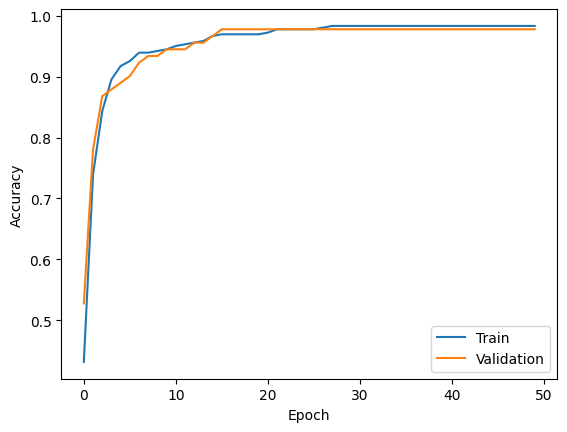

In [76]:
test_loss, test_accuracy = model.evaluate(X_test_scaled, y_test)
print("Test accuracy:", test_accuracy)

plt.plot(history_long.history["accuracy"], label="Train")
plt.plot(history_long.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

#Exersise 4

In [64]:
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

history = model.fit(X_train_scaled, y_train,epochs=10,batch_size=32,validation_split=0.2)

Epoch 1/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 71ms/step - accuracy: 0.9890 - loss: 0.0308 - val_accuracy: 0.9780 - val_loss: 0.0502
Epoch 2/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.9890 - loss: 0.0288 - val_accuracy: 0.9780 - val_loss: 0.0502
Epoch 3/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.9890 - loss: 0.0275 - val_accuracy: 0.9780 - val_loss: 0.0497
Epoch 4/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - accuracy: 0.9890 - loss: 0.0266 - val_accuracy: 0.9780 - val_loss: 0.0485
Epoch 5/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.9918 - loss: 0.0258 - val_accuracy: 0.9780 - val_loss: 0.0475
Epoch 6/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9918 - loss: 0.0247 - val_accuracy: 0.9780 - val_loss: 0.0481
Epoch 7/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.9918 - loss: 0.0239 - val_accuracy: 0.9780 - val_loss: 0.0482
Epoch 8/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.9945 - loss: 0.0228 - val_accuracy: 0.9780 - v

#Exercise 5

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9561 - loss: 0.1175
Test accuracy: 0.9561403393745422


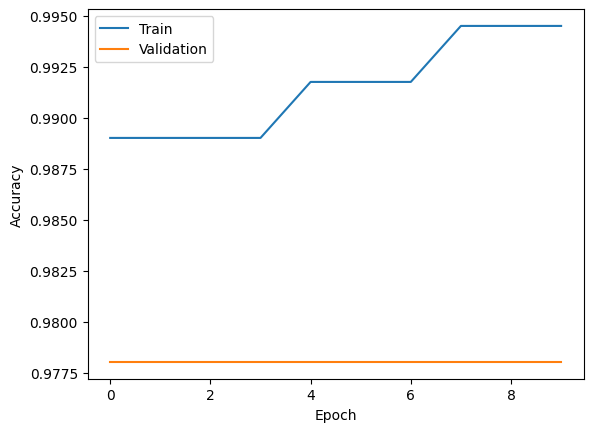

In [65]:
test_loss, test_accuracy = model.evaluate(X_test_scaled, y_test)
print("Test accuracy:", test_accuracy)

plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

(0.9, 1.0)

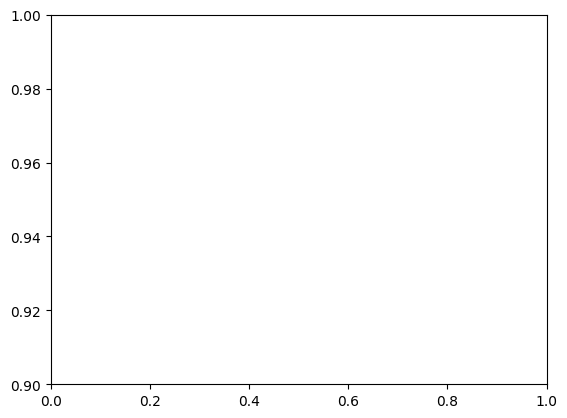

In [66]:
plt.ylim(0.9, 1.0)

I changed the training for 50 epochs instead of 10.

	                      10 epochs	              50 epochs
Test accuracy	           0.9561	                 0.9386
Test loss.       	       0.1887	                 0.1158
Training time	about       2s	                  about 8s

#1. Did accuracy improve? No. Test accuracy went from 0.9561 to 0.9386, a difference of 2 patients out of 114. That is within random variation between runs, so I conclude that more epochs did not help accuracy. The test loss did improve, which means the model became more confident in its predictions.

#2. Did training take longer? Yes, about 4 times longer (8 s vs about 2 s). Exact times vary between runs because Colab shares hardware.

#3. Did the validation curve become less stable? No. The curve is smooth. Both curves rise quickly in the first 10 epochs and then flatten from about epoch 20, with training and validation accuracy close together at about 0.97. The extra 30 or so epochs added almost nothing, so for this small dataset 10 to 20 epochs is enough.

#Relection

1. Why do we scale the data before training?
The features have very different ranges. Some are in the thousands (like area) and some are tiny decimals (like smoothness). Without scaling, the large-valued features dominate and the network trains slowly or unstably. StandardScaler puts every feature on a similar scale (mean 0, standard deviation 1). We fit the scaler on the training data only, so no information from the test set leaks into training.

2. Why does the output layer use sigmoid?
This is a binary classification problem (malignant or benign). Sigmoid squashes the output into a number between 0 and 1, which can be read as the probability that the tumor is benign. It also pairs with the binary_crossentropy loss. A prediction above 0.5 is classed as benign, and below 0.5 as malignant.

3. What is the role of validation_split?
It holds out part of the training data (here 20%) and doesn’t train on it. After each epoch the model is tested on that held-out part, which gives val_accuracy and val_loss. Comparing them with the training numbers shows whether the model is overfitting, meaning it does well on data it has seen but worse on new data. The test set stays untouched until the very end.

4. What does accuracy tell us?
Accuracy is the fraction of predictions that are correct. My model got 0.9561 on the test set, which means about 109 of 114 patients were classified correctly. It has limits, though. It treats all mistakes equally, and in cancer screening, missing a malignant tumor is much worse than a false alarm. It can also mislead when the classes are imbalanced. About 63% of this dataset is benign, so a model that always said “benign” would score 63%. In a real setting I’d also check precision, recall and the confusion matrix.
